In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/content/sample_data/tyre_temp_2024.csv')
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2921 entries, 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Data columns (total 1 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Tyre_Temperature_C  2921 non-null   float64
dtypes: float64(1)
memory usage: 45.6 KB


In [5]:
df

,Tyre_Temperature_C
Date,
2024-01-01 00:00:00,28.105741
2024-01-01 03:00:00,26.512028
2024-01-01 06:00:00,27.676788
2024-01-01 09:00:00,38.600148
2024-01-01 12:00:00,37.608504
...,...
2024-12-30 12:00:00,31.398674
2024-12-30 15:00:00,37.647517
2024-12-30 18:00:00,34.985475


In [6]:
import numpy as np
import pandas as pd

def create_features(df):
    df["Hour"] = df.index.hour
    df["DayOfWeek"] = df.index.dayofweek
    df["Month"] = df.index.month

    df["isWeekend"] = df["DayOfWeek"].apply(lambda x: 1 if x >= 5 else 0)
    df["isRushHour"] = df["Hour"].apply(lambda x: 1 if 7 <= x <= 9 or 17 <= x <= 19 else 0)

    df['hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)

    df['day_sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7)
    df['day_cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7)

    df['month_sin'] = np.sin(2 * np.pi * (df['Month'] - 1) / 12)
    df['month_cos'] = np.cos(2 * np.pi * (df['Month'] - 1) / 12)

    df['tp_lag_24h'] = df['Tyre_Temperature_C'].shift(24)

    df['tp_rolling_avg_3d'] = df['Tyre_Temperature_C'].rolling(window=72).mean()
    df.drop(['Hour', 'DayOfWeek', 'Month'], axis=1, inplace=True)
    df.dropna(inplace=True)

    return df


In [7]:
# Apply feature engineering function
df = create_features(df)

features = ['Tyre_Temperature_C', 'isWeekend', 'isRushHour',
            'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
            'month_sin', 'month_cos', 'tp_lag_24h',
            'tp_rolling_avg_3d']

target = 'Tyre_Temperature_C'

In [8]:
train_size = int(len(df) * 0.1)
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

In [9]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_df[features])
test_scaled = scaler.transform(test_df[features])

In [10]:
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size - 8):  # Predict 8 readings (24 hours ahead)
        X.append(data[i:i+window_size])
        y.append(data[i+window_size:i+window_size+8, 0])  # Next 8 pressure values
    return np.array(X), np.array(y)

In [11]:
df.head()

,Tyre_Temperature_C,isWeekend,isRushHour,hour_sin,hour_cos,day_sin,day_cos,month_sin,month_cos,tp_lag_24h,tp_rolling_avg_3d
Date,,,,,,,,,,,
2024-01-09 21:00:00,31.071312,0,0,-0.707107,7.071068e-01,0.781831,0.623490,0.0,1.0,35.404772,30.027638
2024-01-10 00:00:00,28.956488,0,0,0.000000,1.000000e+00,0.974928,-0.222521,0.0,1.0,21.649906,30.039454
2024-01-10 03:00:00,28.247796,0,0,0.707107,7.071068e-01,0.974928,-0.222521,0.0,1.0,26.516892,30.063562
2024-01-10 06:00:00,21.682291,0,0,1.000000,6.123234e-17,0.974928,-0.222521,0.0,1.0,25.238090,29.980305
2024-01-10 09:00:00,39.346340,0,1,0.707107,-7.071068e-01,0.974928,-0.222521,0.0,1.0,33.302874,29.990669


In [12]:
window_size = 56  # 1 week lookback for 8 readings per day
X_train, y_train = create_sequences(train_scaled, window_size)
X_test, y_test = create_sequences(test_scaled, window_size)

In [18]:
from tensorflow.keras.layers import Bidirectional, BatchNormalization

model = Sequential([
    Bidirectional(LSTM(128, return_sequences=True), input_shape=(window_size, len(features))),
    BatchNormalization(),  # Stabilizes training
    Dropout(0.2),

    # Stacked LSTM with reduced units
    Bidirectional(LSTM(64, return_sequences=True)),
    BatchNormalization(),
    Dropout(0.3),

    # Final LSTM layer
    LSTM(32),

    # Intermediate dense layer for non-linear mapping
    Dense(64, activation='relu'),
    Dropout(0.2),

    # Output layer for 24-hour prediction
    Dense(8)
])

In [19]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [20]:
from tensorflow.keras.callbacks import EarlyStopping

# Define EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the model with early stopping
history = model.fit(X_train, y_train,
                    epochs=50,
                    batch_size=32,
                    validation_split=0.1,
                    verbose=1,
                    callbacks=[early_stopping])

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 144ms/step - loss: 0.2255 - mae: 0.3827 - val_loss: 0.1961 - val_mae: 0.3979
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0941 - mae: 0.2500 - val_loss: 0.1792 - val_mae: 0.3758
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0831 - mae: 0.2336 - val_loss: 0.1543 - val_mae: 0.3427
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0791 - mae: 0.2302 - val_loss: 0.1303 - val_mae: 0.3067
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0743 - mae: 0.2207 - val_loss: 0.1111 - val_mae: 0.2762
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0716 - mae: 0.2197 - val_loss: 0.0899 - val_mae: 0.2428
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0733 - mae: 0.2227 - val_loss: 0.0738 - val_mae: 0.2204
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0651 - mae: 0.2114 - val_loss: 0.0598 - val_mae: 0.2005
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0656 - mae: 0.2100 -

In [21]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f'Test Loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}')

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1045 - mae: 0.2574
Test Loss: 0.1715, Test MAE: 0.3414


In [22]:
def inverse_scale_predictions(scaled_predictions, scaler, feature_index=0):
    n_samples, n_steps = scaled_predictions.shape

    dummy = np.zeros((n_samples * n_steps, len(features)))

    dummy[:, feature_index] = scaled_predictions.flatten()

    inverse_scaled = scaler.inverse_transform(dummy)

    return inverse_scaled[:, feature_index].reshape(n_samples, n_steps)

In [26]:
# Make predictions
test_predictions = model.predict(X_test[:1])  # Predict first test sample
test_predictions = inverse_scale_predictions(test_predictions, scaler)

# Get the corresponding timestamps for the predictions
prediction_timestamps = test_df.index[window_size:window_size+24]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


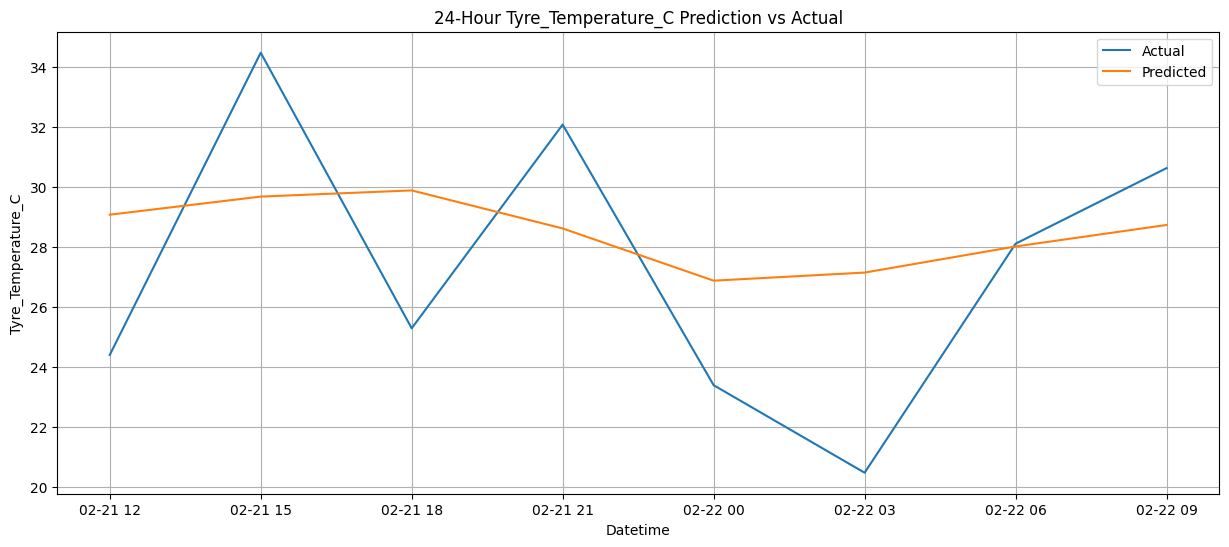

In [27]:
plt.figure(figsize=(15, 6))
plt.plot(test_df.index[window_size:window_size+8], test_df['Tyre_Temperature_C'].iloc[window_size:window_size+8], label='Actual')
plt.plot(test_df.index[window_size:window_size+8], test_predictions.flatten()[:8], label='Predicted')  # First 8 predictions
plt.title('24-Hour Tyre_Temperature_C Prediction vs Actual')
plt.xlabel('Datetime')
plt.ylabel('Tyre_Temperature_C')
plt.legend()
plt.grid(True)
plt.show()


In [28]:
model.save("Final_Tyre_Temp_Prediction_Model.h5")

In [29]:
import pickle

with open('scaler_TP.pkl', 'wb') as f:
    pickle.dump(scaler, f)